In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [101]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


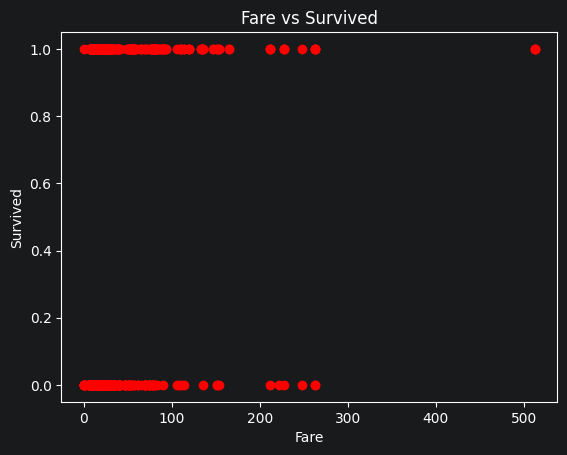

In [102]:
%matplotlib inline
plt.title("Fare vs Survived")
plt.xlabel("Fare")
plt.ylabel("Survived")
plt.scatter(df["Fare"], df["Survived"], color="red", marker="o")

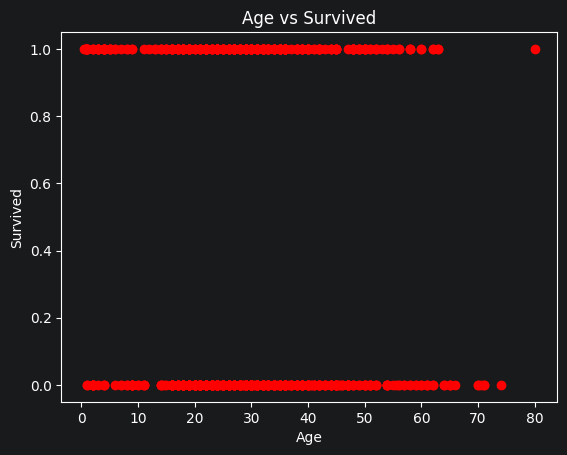

In [103]:
%matplotlib inline
plt.title("Age vs Survived")
plt.xlabel("Age")
plt.ylabel("Survived")
plt.scatter(df["Age"], df["Survived"], color="red", marker="o")

In [104]:
x = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
y = df["Survived"].copy()

In [105]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

Embarked_n = le.fit_transform(df["Embarked"])
Sex_n = le.fit_transform(df["Sex"])

x.loc[:, "Embarked_n"] = Embarked_n
x.loc[:, "Sex_n"] = Sex_n

x.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Embarked_n,Sex_n
0,3,male,22.0,1,0,7.2500,S,2,1
1,1,female,38.0,1,0,71.2833,C,0,0
2,3,female,26.0,0,0,7.9250,S,2,0
3,1,female,35.0,1,0,53.1000,S,2,0
4,3,male,35.0,0,0,8.0500,S,2,1


In [106]:
x.loc[:, "Age"] = x["Age"].fillna(x["Age"].median())
x["Age"]

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888    28.0
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [107]:
final = x.drop(["Sex", "Embarked"], axis=1)

In [108]:
len(final)

891

In [109]:
len(y)

891

In [110]:
final.head()

,Pclass,Age,SibSp,Parch,Fare,Embarked_n,Sex_n
0,3,22.0,1,0,7.2500,2,1
1,1,38.0,1,0,71.2833,0,0
2,3,26.0,0,0,7.9250,2,0
3,1,35.0,1,0,53.1000,2,0
4,3,35.0,0,0,8.0500,2,1


In [111]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(final, y, test_size = 0.2)

In [112]:
type(y_train)

pandas.core.series.Series

In [113]:
x_train.head()

,Pclass,Age,SibSp,Parch,Fare,Embarked_n,Sex_n
361,2,29.0,1,0,27.7208,0,1
676,3,24.5,0,0,8.0500,2,1
314,2,43.0,1,1,26.2500,2,1
696,3,44.0,0,0,8.0500,2,1
657,3,32.0,1,1,15.5000,1,0


In [114]:
x_train.isnull().sum()

Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked_n    0
Sex_n         0
dtype: int64

In [115]:
# Checking with Logistic regression
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [116]:
logistic_model.score(x_test, y_test)

0.8156424581005587

In [117]:
sample = pd.DataFrame(
    [[2, 30, 0, 0, 13, 2, 1]],
    columns=[
        'Pclass',
        'Age',
        'SibSp',
        'Parch',
        'Fare',
        'Embarked_n',
        'Sex_n'
    ]
)

logistic_model.predict(sample)

array([0])

In [122]:
y_predicted = logistic_model.predict(x_test)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_predicted)
cm

array([[90, 14],
       [19, 56]])

Text(95.72222222222221, 0.5, 'True')

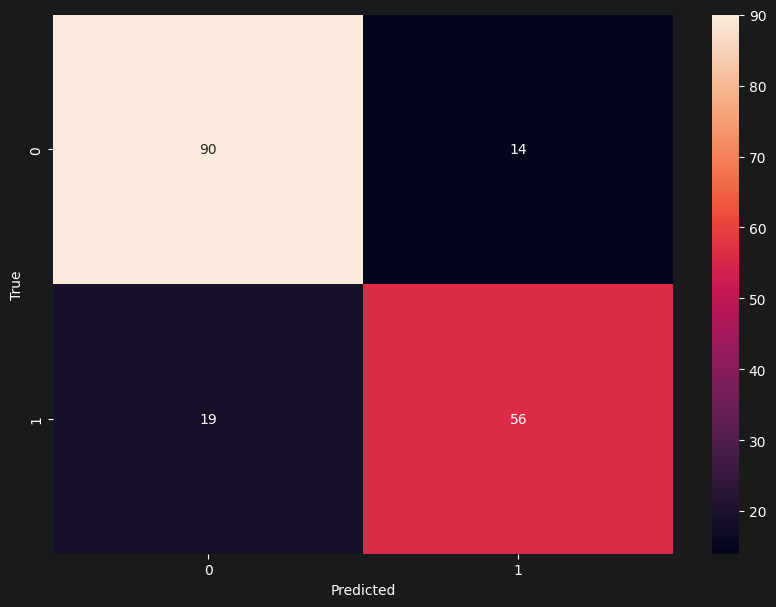

In [123]:

import seaborn as sns
plt.figure(figsize = (10,7))
sns.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("True")

In [125]:
# Checking with decision tree
from sklearn.tree import DecisionTreeClassifier

model_decision = DecisionTreeClassifier()
model_decision.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [126]:
model_decision.score(x_test, y_test)

0.8379888268156425

In [127]:
y_predicted1 = logistic_model.predict(x_test)

cm1 = confusion_matrix(y_test, y_predicted1)
cm1

array([[90, 14],
       [19, 56]])

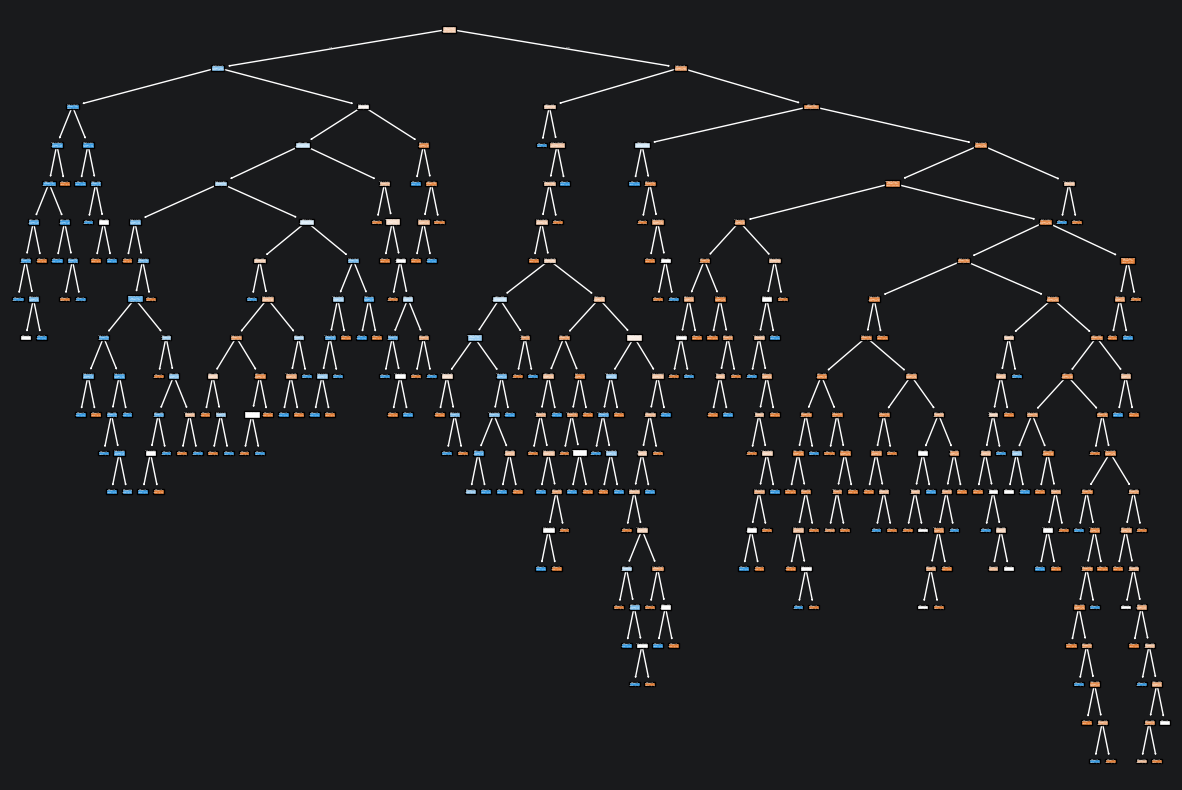

In [128]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15,10))

tree.plot_tree(
    model_decision,
    feature_names=x_train.columns,
    filled=True
)

plt.show()

In [129]:
print("Logistic:", logistic_model.score(x_test, y_test))
print("Tree:", model_decision.score(x_test, y_test))

Logistic: 0.8156424581005587
Tree: 0.8379888268156425


In [130]:
print("Train:", model_decision.score(x_train, y_train))
print("Test :", model_decision.score(x_test, y_test))

Train: 0.9831460674157303
Test : 0.8379888268156425


In [131]:
# Checking with random forest

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(x_train, y_train)

print("Train:", rf.score(x_train, y_train))
print("Test :", rf.score(x_test, y_test))

Train: 0.9831460674157303
Test : 0.8659217877094972
